<a href="https://colab.research.google.com/github/ks148678-beep/Data-Warehousing-and-Data-Mining/blob/main/cleaning_causes_of_road_accidents%20with%20heatmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# STEP 1: LOAD & CLEAN (5 Marks)
# Load with multi-level headers (Row 0 is Year, Row 1 is the Crash Metric)
df = pd.read_excel('/content/causes-of-road-traffic-crashes-in-uganda-2011-2020 (1) (4) (1).xlsx', header=[0, 1])
print("Original shape with MultiIndex:", df.shape)

# Clean up column index
# Level 0 contains years (or Unnamed/Causes), Level 1 contains the actual metrics
# Fill forward the year names in Level 0 since they are merged horizontally
new_cols = []
current_year = None
for col in df.columns:
    year_val = str(col[0]).strip()
    metric_val = str(col[1]).strip()

    # If the top level contains 'Causes', it's the category column
    if 'Causes' in year_val or 'Unnamed' in year_val:
        new_cols.append(('Causes_of_Crashes', 'Causes_of_Crashes'))
    else:
        # Extract 4-digit year from the parent column name if present
        import re
        match = re.search(r'\d{4}', year_val)
        if match:
            current_year = match.group(0)
        new_cols.append((current_year, metric_val))

df.columns = pd.MultiIndex.from_tuples(new_cols)

# Filter out total row from first column level
# Since it's a MultiIndex, we slice using the 'Causes_of_Crashes' column
df = df[~df[('Causes_of_Crashes', 'Causes_of_Crashes')].astype(str).str.contains('Total', case=False, na=False)]
df = df.drop_duplicates()
df = df.fillna(0)

Original shape with MultiIndex: (14, 38)


In [30]:
# STEP 2: GROUP INTO 3 CAUSES
def map_cause(cause):
    cause = str(cause).lower()
    if any(x in cause for x in ['careless','reckless','speed','pedestrian','passenger fall','alcohol','overtaking']):
        return 'Population_Behavior'
    elif any(x in cause for x in ['dmc','dangerous loading','tyre','brake']):
        return 'Motor_Vehicle_Condition'
    else:
        return 'Road_Environment'

# Map the cause categories
df['Cause_Group'] = df[('Causes_of_Crashes', 'Causes_of_Crashes')].apply(map_cause)

# Gather data for each year (2011 to 2020) using 'Total' metrics
# We want to sum up the values of 'Total' crash columns per year group
year_data = []
years = [str(y) for y in range(2011, 2021)]

for year in years:
    # Locate the column corresponding to (year, 'Total') if it exists
    # Note: some sheets might use 'Total' or another variation
    matching_col = None
    for col in df.columns:
        if col[0] == year and 'Total' in col[1]:
            matching_col = col
            break

    if matching_col:
        temp_df = pd.DataFrame({
            'Causes_of_Crashes': df[('Causes_of_Crashes', 'Causes_of_Crashes')],
            'Cause_Group': df['Cause_Group'],
            'Year': int(year),
            'Count': pd.to_numeric(df[matching_col], errors='coerce').fillna(0)
        })
        year_data.append(temp_df)

if year_data:
    df_long = pd.concat(year_data, ignore_index=True)
    grouped = df_long.groupby(['Year', 'Cause_Group'])['Count'].sum().reset_index()
    final = grouped.pivot(index='Year', columns='Cause_Group', values='Count').reset_index()
    final['Total_Road_Traffic_Accidents'] = final.sum(axis=1, numeric_only=True)
    print(final.head(10))
    final.to_csv('cleaned_uganda_crashes_2011_2020.csv', index=False)
else:
    print("Error: No year columns matched.")

Cause_Group  Year  Motor_Vehicle_Condition  Population_Behavior  \
0            2011                    648.0              17981.0   
1            2012                    527.0              15535.0   
2            2013                    515.0              15494.0   
3            2014                    542.0              16398.0   
4            2015                    607.0              15923.0   
5            2016                     56.0              13638.0   
6            2017                    637.0              12096.0   
7            2018                    404.0              11791.0   
8            2019                    429.0              11912.0   
9            2020                    507.0              11039.0   

Cause_Group  Road_Environment  Total_Road_Traffic_Accidents  
0                      3362.0                       24002.0  
1                      3736.0                       21810.0  
2                      3225.0                       21247.0  
3             


Correlation Matrix:
 Cause_Group                   Population_Behavior  Road_Environment  \
Cause_Group                                                           
Population_Behavior                      1.000000          0.914451   
Road_Environment                         0.914451          1.000000   
Motor_Vehicle_Condition                  0.331613          0.502692   
Total_Road_Traffic_Accidents             0.984138          0.970221   

Cause_Group                   Motor_Vehicle_Condition  \
Cause_Group                                             
Population_Behavior                          0.331613   
Road_Environment                             0.502692   
Motor_Vehicle_Condition                      1.000000   
Total_Road_Traffic_Accidents                 0.441143   

Cause_Group                   Total_Road_Traffic_Accidents  
Cause_Group                                                 
Population_Behavior                               0.984138  
Road_Environment         

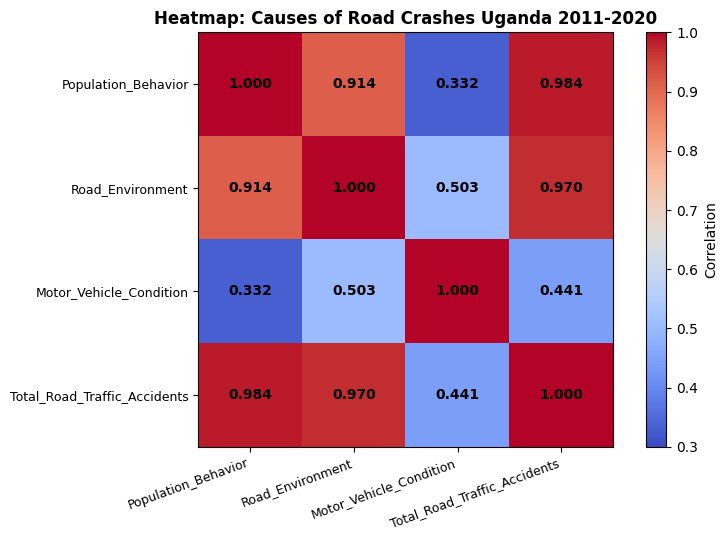

In [31]:

# url = 'https://raw.githubusercontent.com/_https://github.com/ks148678-beep/Data-Warehousing-and-Data-Mining/blob/main/CLEANED_uganda_rtc_2011_2/cuu-traffic-data-warehouse/main/cleaned_uganda_crashes_2011_2020.csv'
# final = pd.read_csv(url)

cols = ['Population_Behavior','Road_Environment','Motor_Vehicle_Condition','Total_Road_Traffic_Accidents']
corr = final[cols].corr()
print("\nCorrelation Matrix:\n", corr)

# STEP 4: HEATMAP
fig, ax = plt.subplots(figsize=(8,5.5))
im = ax.imshow(corr.values, cmap='coolwarm', vmin=0.3, vmax=1.0)
plt.colorbar(im, ax=ax, label='Correlation')

ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=20, ha='right', fontsize=9)
ax.set_yticklabels(cols, fontsize=9)

for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.values[i,j]:.3f}", ha='center', va='center', fontweight='bold')

plt.title('Heatmap: Causes of Road Crashes Uganda 2011-2020', fontweight='bold')
plt.tight_layout()
plt.savefig('heatmap_final.png', dpi=300)
plt.show()